# **Group Project**

### Objective:
To transform a massive, memory-heavy transaction dataset (Big Data) into a lightweight, daily aggregated dataset by calculating the total number of rides per day alongside their corresponding weather conditions.

In [1]:
import pandas as pd

# Read only the columns needed from the local full-year dataset
path = 'df_merged_2025_FULL_YEAR.csv'

# Strategy: chunk and aggregate on the fly to save RAM
chunk_size = 250000
daily_records = []

# Note: We use uppercase 'DATE' to match the merged weather column
for chunk in pd.read_csv(path, chunksize=chunk_size, 
                         usecols=['started_at', 'DATE', 'TMAX', 'PRCP', 'AWND']):
    chunk['DATE'] = pd.to_datetime(chunk['DATE'])
    
    # Count rides per date within chunk
    agg = chunk.groupby('DATE').agg(
        rides=('started_at', 'count'),
        TMAX=('TMAX', 'first'),
        PRCP=('PRCP', 'first'),
        AWND=('AWND', 'first')
    ).reset_index()
    daily_records.append(agg)

# Combine all chunks and re-aggregate for the final daily counts
df_daily = pd.concat(daily_records).groupby('DATE').agg(
    Total_Daily_Rides=('rides', 'sum'),
    TMAX=('TMAX', 'first'),
    PRCP=('PRCP', 'first'),
    AWND=('AWND', 'first')
).reset_index()

print(f"Dataset shape: {df_daily.shape} (Should be 365 rows for a full year)")
display(df_daily.head())

Dataset shape: (365, 5) (Should be 365 rows for a full year)


,DATE,Total_Daily_Rides,TMAX,PRCP,AWND
0,2025-01-01,51442,51,0.0,8.28
1,2025-01-02,71779,43,0.0,9.62
2,2025-01-03,75361,39,0.0,7.83
3,2025-01-04,55389,33,0.0,10.07
4,2025-01-05,52177,33,0.0,8.50


### Objective: 
To quantify the relationship between weather variables and daily ridership by training a baseline Linear Regression model, and to visually validate these mathematical trends using scatter plots.

### Question:
How accurately can a baseline Linear Regression model predict total daily ridership using only core weather features (maximum temperature, precipitation, and wind speed), and what is the individual impact weight of each feature?

Loading and aggregating the full-year dataset...
Aggregated Shape: (360, 5) (Should be roughly 365 days)

--- Machine Learning Results ---
R²: 0.7765077061787597

Coefficients:
  TMAX: 2031.40
  PRCP: -38964.09
  AWND: -1181.26

Correlations with Total_Daily_Rides:
Total_Daily_Rides    1.000000
TMAX                 0.844663
PRCP                -0.221805
AWND                -0.523186
Name: Total_Daily_Rides, dtype: float64

--- Generating Charts ---


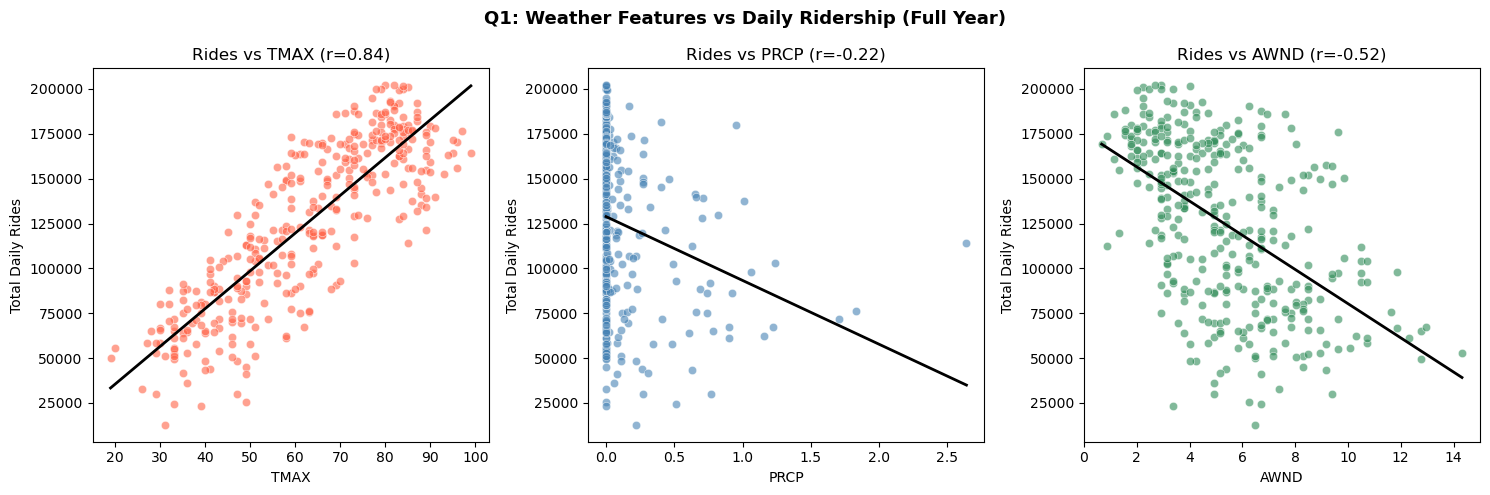

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1. READ AND AGGREGATE THE FULL YEAR DATA
print("Loading and aggregating the full-year dataset...")
path = 'df_merged_2025_FULL_YEAR.csv' # Updated to your local 6GB file

chunk_size = 100_000
daily_records = []

# Updated 'date' to uppercase 'DATE'
for chunk in pd.read_csv(path, chunksize=chunk_size,
                          usecols=['started_at', 'DATE', 'TMAX', 'PRCP', 'AWND']):
    chunk['DATE'] = pd.to_datetime(chunk['DATE'])
    
    # Count rides per date within chunk
    agg = chunk.groupby('DATE').agg(
        rides=('started_at', 'count'),
        TMAX=('TMAX', 'first'),
        PRCP=('PRCP', 'first'),
        AWND=('AWND', 'first')
    ).reset_index()
    daily_records.append(agg)

# Combine all chunks and re-aggregate
df_daily = pd.concat(daily_records).groupby('DATE').agg(
    Total_Daily_Rides=('rides', 'sum'),
    TMAX=('TMAX', 'first'),
    PRCP=('PRCP', 'first'),
    AWND=('AWND', 'first')
).reset_index()

# *** THE FIX: Drop missing weather data so the model doesn't crash ***
df_daily_clean = df_daily.dropna()

print(f"Aggregated Shape: {df_daily_clean.shape} (Should be roughly 365 days)")

# 2. MACHINE LEARNING: LINEAR REGRESSION
print("\n--- Machine Learning Results ---")
# Features for Q1: TMAX, PRCP, AWND
X = df_daily_clean[['TMAX', 'PRCP', 'AWND']]
y = df_daily_clean['Total_Daily_Rides']

model = LinearRegression().fit(X, y)
print("R²:", r2_score(y, model.predict(X)))
print("\nCoefficients:")
for feat, coef in zip(X.columns, model.coef_):
    print(f"  {feat}: {coef:.2f}")

# Correlation check for Hypothesis 1
print("\nCorrelations with Total_Daily_Rides:")
print(df_daily_clean[['Total_Daily_Rides', 'TMAX', 'PRCP', 'AWND']].corr()['Total_Daily_Rides'])


# 3. EXPLORATORY DATA ANALYSIS CHARTS
print("\n--- Generating Charts ---")
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, feat, color in zip(axes,
                            ['TMAX', 'PRCP', 'AWND'],
                            ['tomato', 'steelblue', 'seagreen']):
    
    # Use df_daily_clean for the charts!
    ax.scatter(df_daily_clean[feat], df_daily_clean['Total_Daily_Rides'],
               alpha=0.6, color=color, edgecolors='white', linewidth=0.5)
    
    m, b = np.polyfit(df_daily_clean[feat], df_daily_clean['Total_Daily_Rides'], 1)
    x_line = np.linspace(df_daily_clean[feat].min(), df_daily_clean[feat].max(), 100)
    ax.plot(x_line, m * x_line + b, color='black', linewidth=2)
    
    ax.set_xlabel(feat)
    ax.set_ylabel('Total Daily Rides')
    ax.set_title(f'Rides vs {feat} (r={df_daily_clean[feat].corr(df_daily_clean["Total_Daily_Rides"]):.2f})')

# Updated title to reflect the full year
plt.suptitle('Q1: Weather Features vs Daily Ridership (Full Year)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Objective: 
To perform feature engineering on the date column to categorize days into weekdays and weekends, and to subsequently analyze whether commuter ridership (weekdays) is more resilient to adverse weather (precipitation) than recreational ridership (weekends).

### Question:
Does the impact of adverse weather conditions, specifically precipitation, on daily ridership volume differ significantly between weekdays (commuter-heavy) and weekends (recreation-heavy)?

=== Weekday correlations with Weather ===
Total_Daily_Rides    1.000000
PRCP                -0.239306
AWND                -0.548693
Name: Total_Daily_Rides, dtype: float64

=== Weekend correlations with Weather ===
Total_Daily_Rides    1.000000
PRCP                -0.176522
AWND                -0.507429
Name: Total_Daily_Rides, dtype: float64


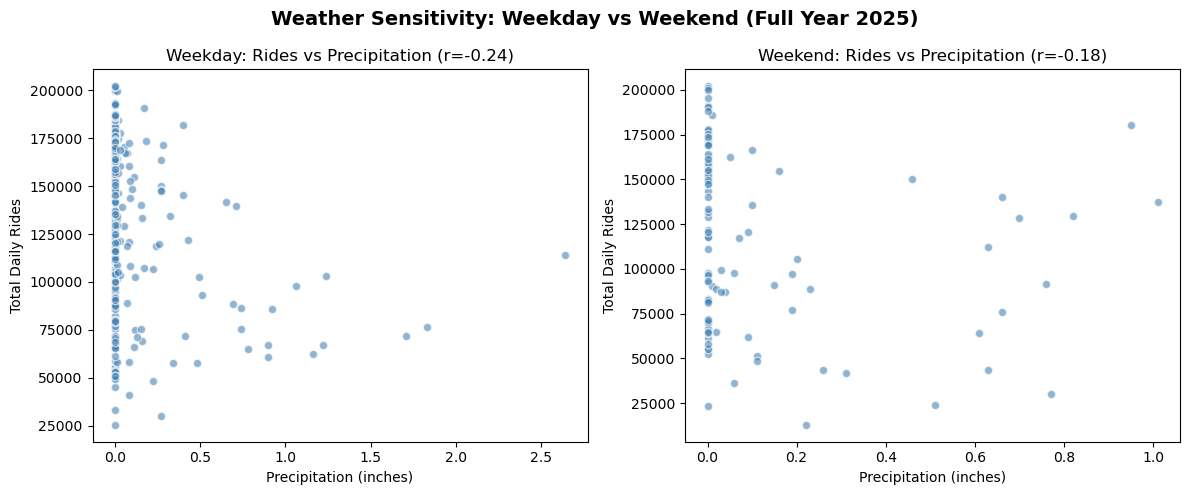

In [4]:
# Create a clean copy to prevent pandas "SettingWithCopy" warnings
df_daily_clean = df_daily_clean.copy()

# Add temporal features using the correct uppercase 'DATE'
df_daily_clean['day_of_week'] = df_daily_clean['DATE'].dt.dayofweek  # 0=Mon, 6=Sun
df_daily_clean['is_weekend'] = df_daily_clean['day_of_week'].isin([5, 6]).astype(int)
df_daily_clean['month'] = df_daily_clean['DATE'].dt.month

# Split and compare weather sensitivity
weekday = df_daily_clean[df_daily_clean['is_weekend'] == 0]
weekend = df_daily_clean[df_daily_clean['is_weekend'] == 1]

print("=== Weekday correlations with Weather ===")
print(weekday[['Total_Daily_Rides', 'PRCP', 'AWND']].corr()['Total_Daily_Rides'])

print("\n=== Weekend correlations with Weather ===")
print(weekend[['Total_Daily_Rides', 'PRCP', 'AWND']].corr()['Total_Daily_Rides'])

# Visualize
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (label, subset) in zip(axes, [('Weekday', weekday), ('Weekend', weekend)]):
    ax.scatter(subset['PRCP'], subset['Total_Daily_Rides'], alpha=0.6, color='steelblue', edgecolors='white')
    
    # Added correlation score directly into the title so your team can see the exact math!
    r_score = subset['PRCP'].corr(subset['Total_Daily_Rides'])
    ax.set_title(f'{label}: Rides vs Precipitation (r={r_score:.2f})')
    
    ax.set_xlabel('Precipitation (inches)')
    ax.set_ylabel('Total Daily Rides')

plt.suptitle('Weather Sensitivity: Weekday vs Weekend (Full Year 2025)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Objective: 
To segment the massive raw dataset by user type (annual members vs. casual riders) and aggregate daily ridership, in order to quantify and compare how differently these two distinct customer groups react to daily weather fluctuations.

### Question:
Is there a statistically significant difference in weather sensitivity, particularly regarding precipitation and temperature between annual subscribers (Members) and short-term users (Casual riders) when analyzing daily ridership volume across a full calendar year?

In [5]:
import pandas as pd

print("Aggregating the full-year dataset by Member Type... (This might take a minute)")

# Make sure it points to your massive full-year file
path = 'df_merged_2025_FULL_YEAR.csv'

# Re-aggregate by DATE AND member type
daily_records_by_type = []

# Updated to uppercase 'DATE'
for chunk in pd.read_csv(path, chunksize=250_000,
                          usecols=['started_at', 'DATE', 'TMAX', 'PRCP', 'AWND', 'member_casual']):
    
    chunk['DATE'] = pd.to_datetime(chunk['DATE'])
    
    # Group by both DATE and member_casual
    agg = chunk.groupby(['DATE', 'member_casual']).agg(
        rides=('started_at', 'count'),
        TMAX=('TMAX', 'first'),
        PRCP=('PRCP', 'first'),
        AWND=('AWND', 'first')
    ).reset_index()
    daily_records_by_type.append(agg)

# Combine all chunks and re-aggregate
df_by_type = pd.concat(daily_records_by_type).groupby(['DATE', 'member_casual']).agg(
    Total_Daily_Rides=('rides', 'sum'),
    TMAX=('TMAX', 'first'),
    PRCP=('PRCP', 'first'),
    AWND=('AWND', 'first')
).reset_index()

# *** THE FIX: Drop missing weather data to keep it clean! ***
df_by_type_clean = df_by_type.dropna().copy()

print(f"\nAggregation complete! Shape: {df_by_type_clean.shape}")

# Compare correlations between Members and Casual riders
for rider_type in ['member', 'casual']:
    subset = df_by_type_clean[df_by_type_clean['member_casual'] == rider_type]
    
    # Calculate the math correlation
    corr = subset[['Total_Daily_Rides', 'PRCP', 'TMAX', 'AWND']].corr()['Total_Daily_Rides']
    
    print(f"\n=== {rider_type.upper()} correlations (Full Year 2025) ===")
    print(corr)

Aggregating the full-year dataset by Member Type... (This might take a minute)

Aggregation complete! Shape: (720, 6)

=== MEMBER correlations (Full Year 2025) ===
Total_Daily_Rides    1.000000
PRCP                -0.229794
TMAX                 0.786295
AWND                -0.486888
Name: Total_Daily_Rides, dtype: float64

=== CASUAL correlations (Full Year 2025) ===
Total_Daily_Rides    1.000000
PRCP                -0.156073
TMAX                 0.824619
AWND                -0.511144
Name: Total_Daily_Rides, dtype: float64


### Objective: 
To rigorously evaluate and compare the predictive performance of different machine learning algorithms (Linear Regression vs. Decision Trees) in forecasting daily ridership, using feature scaling and 5-fold cross-validation to ensure the models generalize reliably to unseen data.

### Question:
Which machine learning algorithm, a parametric model (Linear Regression) or a non-parametric model (Decision Tree), provides a more accurate and robust prediction of daily ridership when accounting for both weather conditions and temporal temporal features?

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
import numpy as np

print("Training models on the Full-Year 2025 dataset...")

# *** THE FIX: Use df_daily_clean so the model doesn't crash from NaNs! ***
features = ['TMAX', 'PRCP', 'AWND', 'is_weekend', 'month', 'day_of_week']
X = df_daily_clean[features]
y = df_daily_clean['Total_Daily_Rides']

# Scale the features (Important for Linear Regression!)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Define the models we want to compare
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree (depth=3)': DecisionTreeRegressor(max_depth=3, random_state=42),
    'Decision Tree (depth=5)': DecisionTreeRegressor(max_depth=5, random_state=42),
}

# Run 5-Fold Cross Validation
print("\n=== 5-Fold Cross-Validated R² Scores (Full Year 2025) ===")
for name, model in models.items():
    # cv=5 means it splits the 365 days into 5 chunks, trains on 4, and tests on 1, then repeats!
    scores = cross_val_score(model, X_scaled, y, cv=5, scoring='r2')
    print(f"{name}: mean={scores.mean():.3f}, std={scores.std():.3f}")

Training models on the Full-Year 2025 dataset...

=== 5-Fold Cross-Validated R² Scores (Full Year 2025) ===
Linear Regression: mean=0.186, std=0.470
Decision Tree (depth=3): mean=0.231, std=0.203
Decision Tree (depth=5): mean=0.353, std=0.189


### Objective: 
To evaluate model generalization and detect potential overfitting by comparing in-sample (training) accuracy against out-of-sample (cross-validated) accuracy, utilizing a randomized K-Fold splitting strategy.

### Question:
How well do the baseline predictive models generalize to unseen weather data, and is there evidence of overfitting when increasing the complexity of the Decision Tree algorithm?

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score, KFold
import numpy as np

# *** THE FIX: Use df_daily_clean so it doesn't crash from missing weather! ***
features = ['TMAX', 'PRCP', 'AWND', 'is_weekend', 'month', 'day_of_week']
X = df_daily_clean[features]
y = df_daily_clean['Total_Daily_Rides']

# *** THE UPGRADE: Because you have the full year, we can use the industry-standard 5-fold! ***
kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree (depth=3)': DecisionTreeRegressor(max_depth=3, random_state=42),
    'Decision Tree (depth=5)': DecisionTreeRegressor(max_depth=5, random_state=42),
}

print("=== 5-Fold Cross-Validated R² Scores (Full Year 2025) ===")
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=kf, scoring='r2')
    print(f"{name}: mean={scores.mean():.3f} ± {scores.std():.3f}")

# Also show train score for comparison
print("\n=== In-Sample R² (no CV) ===")
for name, model in models.items():
    model.fit(X, y)
    print(f"{name}: {model.score(X, y):.3f}")

=== 5-Fold Cross-Validated R² Scores (Full Year 2025) ===
Linear Regression: mean=0.787 ± 0.031
Decision Tree (depth=3): mean=0.733 ± 0.079
Decision Tree (depth=5): mean=0.756 ± 0.067

=== In-Sample R² (no CV) ===
Linear Regression: 0.802
Decision Tree (depth=3): 0.809
Decision Tree (depth=5): 0.904


### Objective: 
To interpret the internal logic of a non-linear machine learning model (Decision Tree) by calculating the relative importance of each feature and visualizing the hierarchical "rules" the algorithm created to predict daily ridership.

### Question:
Which meteorological and temporal features exhibit the highest relative importance in predicting daily ridership, and what are the specific numerical thresholds (e.g., temperature drops or precipitation limits) that trigger major shifts in customer demand?

Building and visualizing the Decision Tree...


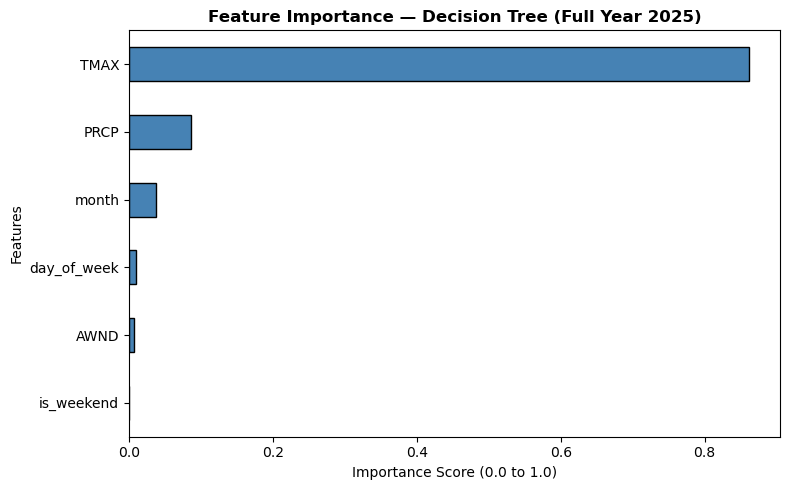

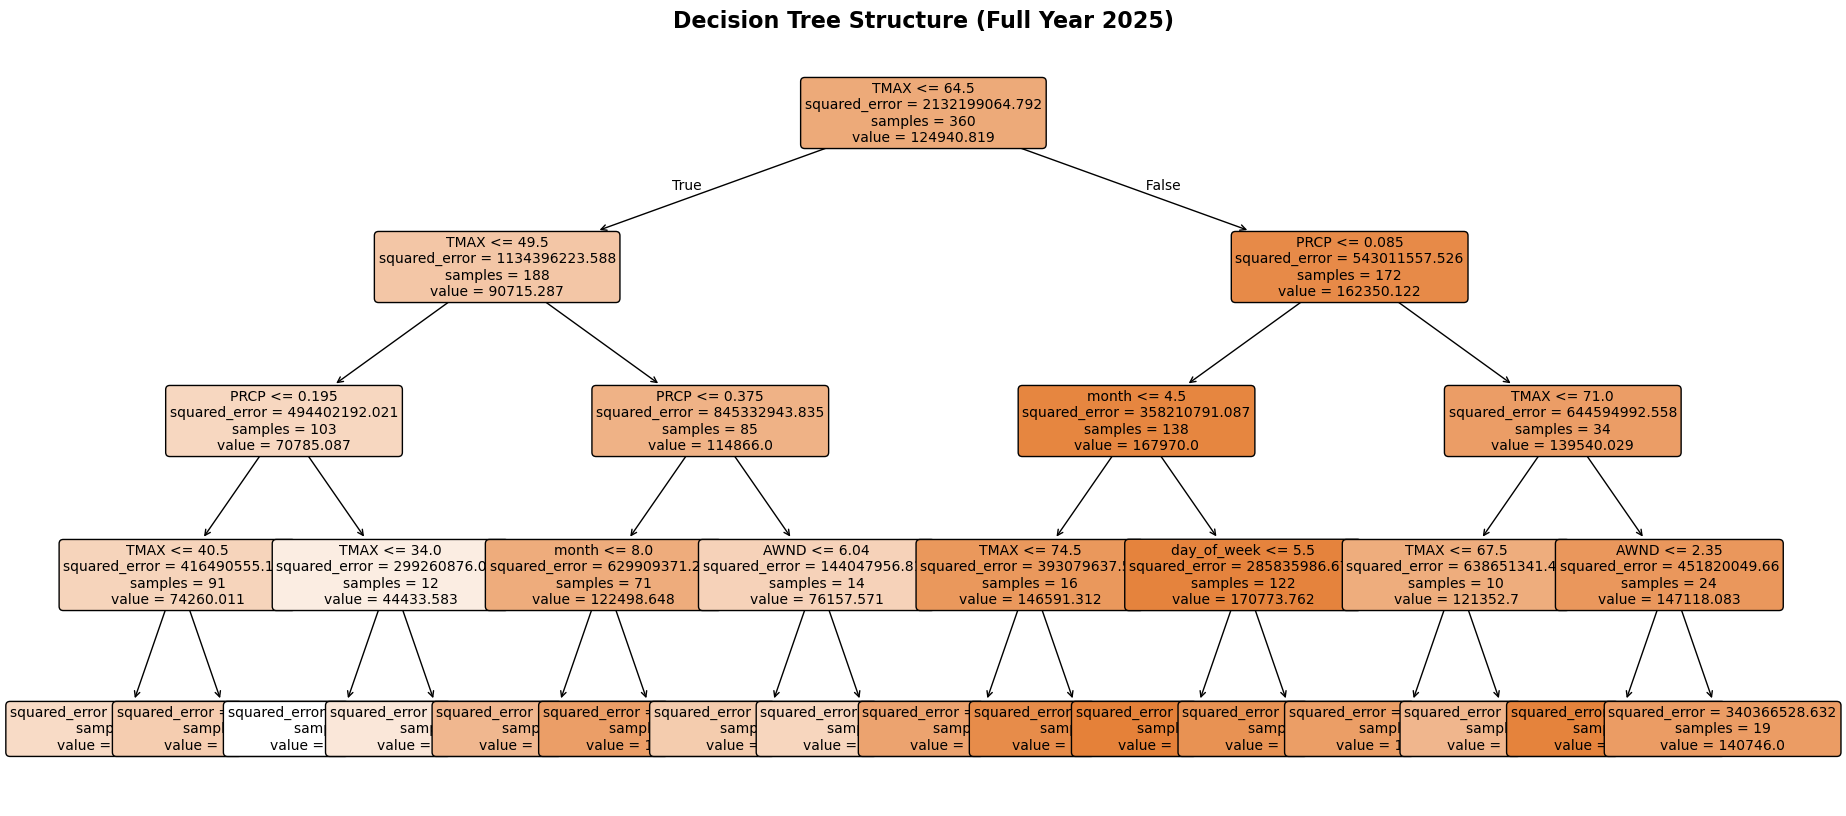

In [9]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
import pandas as pd
import matplotlib.pyplot as plt

print("Building and visualizing the Decision Tree...")

# *** THE FIX: Use df_daily_clean so the model doesn't crash! ***
features = ['TMAX', 'PRCP', 'AWND', 'is_weekend', 'month', 'day_of_week']
X = df_daily_clean[features]
y = df_daily_clean['Total_Daily_Rides']

# Train the Decision Tree (max_depth=4 keeps the final visual readable)
dt = DecisionTreeRegressor(max_depth=4, random_state=42)
dt.fit(X, y)

# 1. Feature Importance Bar Chart
importances = pd.Series(dt.feature_importances_, index=features).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind='barh', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Feature Importance — Decision Tree (Full Year 2025)', fontweight='bold')
ax.set_xlabel('Importance Score (0.0 to 1.0)')
ax.set_ylabel('Features')
plt.tight_layout()
plt.show()

# 2. Visualize the actual Tree Structure
plt.figure(figsize=(22, 10))
plot_tree(dt, feature_names=features, filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree Structure (Full Year 2025)', fontsize=16, fontweight='bold')
plt.show()

### Objective: 
To reframe the continuous ridership prediction problem into a binary classification task (High Demand vs. Low Demand) by using the median daily rides as a threshold, and to evaluate the model's accuracy using standard classification metrics.

### Question:
By reframing daily operational needs into a binary classification framework (Above-Median vs. Below-Median Demand), how effectively can a Decision Tree model predict high-utilization days based solely on environmental and temporal factors?

In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

print("--- Decision Tree Classifier: Predicting High vs Low Demand ---")

# *** THE FIX: Use df_daily_clean to prevent NaN crashes! ***
# We use .copy() just to prevent pandas from giving a "SettingWithCopy" warning
df_class = df_daily_clean.copy()

# Convert to binary: above/below median = high (1) / low (0) demand day
median_rides = df_class['Total_Daily_Rides'].median()
df_class['high_demand'] = (df_class['Total_Daily_Rides'] > median_rides).astype(int)

# Features for Classification
X = df_class[['TMAX', 'PRCP', 'AWND', 'is_weekend', 'month']]
y = df_class['high_demand']

# Train the Classifier
clf = DecisionTreeClassifier(max_depth=3, random_state=42)
clf.fit(X, y)

# Print the evaluation report
print(f"Median Daily Rides (Threshold): {median_rides:,.0f} rides")
print("\nClassification Report (Full Year 2025):")
print(classification_report(y, clf.predict(X)))

--- Decision Tree Classifier: Predicting High vs Low Demand ---
Median Daily Rides (Threshold): 129,756 rides

Classification Report (Full Year 2025):
              precision    recall  f1-score   support

           0       0.98      0.86      0.92       180
           1       0.88      0.98      0.93       180

    accuracy                           0.92       360
   macro avg       0.93      0.92      0.92       360
weighted avg       0.93      0.92      0.92       360



### Objective: 
To visualize macroscopic seasonal trends within the dataset by aggregating daily records into monthly averages, and plotting both ridership volume and maximum temperature on a dual-axis chart to illustrate their correlation over a full calendar year.

### Question:
How does the macroscopic seasonal variation in average maximum temperature correlate with the average daily ridership volume on a month-to-month basis across a full calendar year?

Generating the Monthly Ridership vs Temperature Chart...


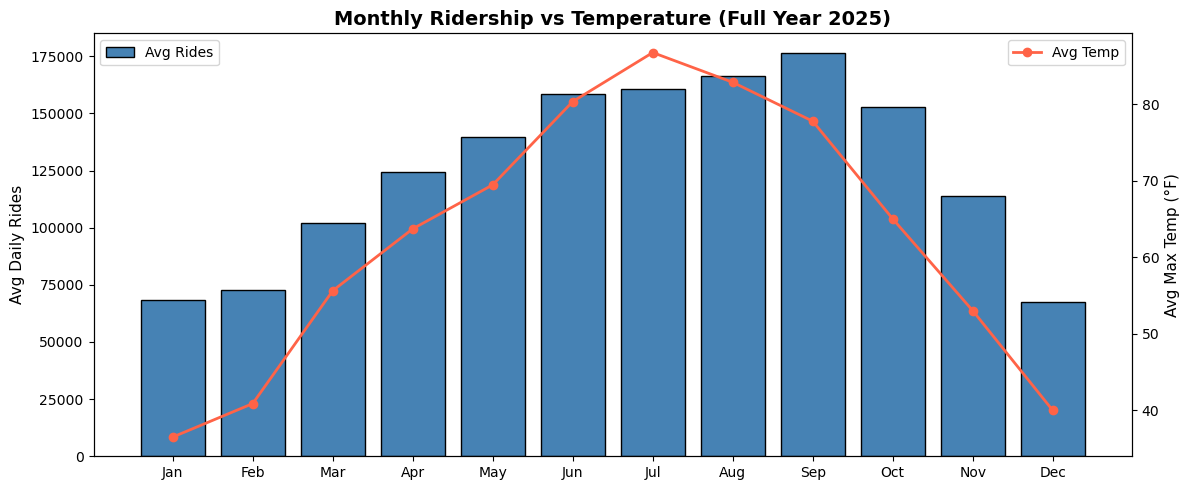


=== Monthly Summary (Full Year 2025) ===
month_name     avg_rides  avg_temp  avg_rain
       Jan  68533.580645 36.516129  0.019677
       Feb  72549.785714 40.892857  0.092857
       Mar 102192.322581 55.645161  0.178065
       Apr 124167.900000 63.733333  0.108333
       May 139545.064516 69.483871  0.212258
       Jun 158641.300000 80.366667  0.082000
       Jul 160889.129032 86.774194  0.130000
       Aug 166537.461538 82.884615  0.085000
       Sep 176238.500000 77.800000  0.092000
       Oct 152656.709677 65.032258  0.131613
       Nov 113869.733333 53.033333  0.069667
       Dec  67467.193548 40.000000  0.109032


In [11]:
import matplotlib.pyplot as plt
import pandas as pd

print("Generating the Monthly Ridership vs Temperature Chart...")

# *** THE FIX: Use our clean full-year dataframe ***
monthly = df_daily_clean.groupby('month').agg(
    avg_rides=('Total_Daily_Rides', 'mean'),
    avg_temp=('TMAX', 'mean'),
    avg_rain=('PRCP', 'mean')
).reset_index()

# *** THE UPGRADE: Map all 12 months for the full year! ***
monthly['month'] = monthly['month'].astype(int)
month_names = {
    1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'May', 6:'Jun',
    7:'Jul', 8:'Aug', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'
}
monthly['month_name'] = monthly['month'].map(month_names)

# Drop any accidental missing data safely
monthly = monthly.dropna(subset=['month_name'])

x = range(len(monthly))
labels = monthly['month_name'].tolist()

# Made the figure slightly wider (12, 5) to comfortably fit all 12 months
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.bar(x, monthly['avg_rides'], color='steelblue', label='Avg Rides', edgecolor='black')
ax1.set_ylabel('Avg Daily Rides', fontsize=11)
ax1.set_xticks(list(x))
ax1.set_xticklabels(labels)

ax2 = ax1.twinx()
ax2.plot(list(x), monthly['avg_temp'].tolist(), color='tomato', marker='o', linewidth=2, label='Avg Temp')
ax2.set_ylabel('Avg Max Temp (°F)', fontsize=11)

ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

# Updated title
plt.title('Monthly Ridership vs Temperature (Full Year 2025)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Print the summary table clearly
print("\n=== Monthly Summary (Full Year 2025) ===")
print(monthly[['month_name', 'avg_rides', 'avg_temp', 'avg_rain']].to_string(index=False))

### Objective: 
To transform continuous temperature data into discrete categories (bins) and calculate the average daily ridership for each interval, allowing for a clear visual identification of the optimal operational weather conditions.

### Question:
At which specific temperature ranges does daily ridership peak, and how significantly do weather extremes (both freezing and extreme heat) quantitatively suppress customer demand?

Binning temperatures for the Full-Year dataset...

=== Average Daily Rides by Temperature (Full Year 2025) ===
temp_bin
<40°F       62096.290909
40-50°F     83566.946429
50-60°F    114658.962264
60-70°F    131380.333333
70-80°F    165741.000000
>80°F      167925.753086
Name: Total_Daily_Rides, dtype: float64


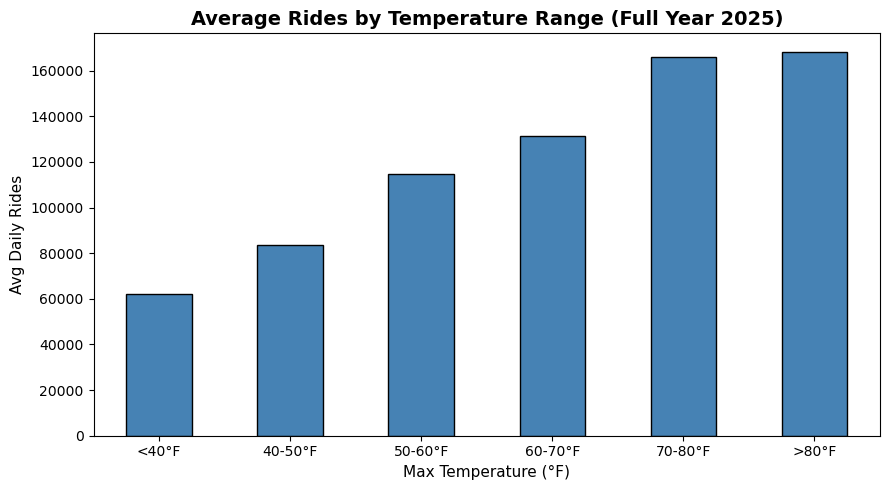

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

print("Binning temperatures for the Full-Year dataset...")

# *** THE FIX: Use df_daily_clean and .copy() to prevent warnings ***
df_temp = df_daily_clean.copy()

# Bin temperature into ranges and see average rides
df_temp['temp_bin'] = pd.cut(df_temp['TMAX'],
                             bins=[0, 40, 50, 60, 70, 80, 100],
                             labels=['<40°F', '40-50°F', '50-60°F', '60-70°F', '70-80°F', '>80°F'])

# Calculate the average rides for each temperature bucket
# (observed=False prevents a new pandas warning)
threshold = df_temp.groupby('temp_bin', observed=False)['Total_Daily_Rides'].mean()

print("\n=== Average Daily Rides by Temperature (Full Year 2025) ===")
print(threshold)

# Visualize the bins
threshold.plot(kind='bar', color='steelblue', edgecolor='black', figsize=(9, 5))

# Updated Title
plt.title('Average Rides by Temperature Range (Full Year 2025)', fontsize=14, fontweight='bold')
plt.ylabel('Avg Daily Rides', fontsize=11)
plt.xlabel('Max Temperature (°F)', fontsize=11)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()